# Anomalous Hall conductivity of metals
A ferromagnetic metal shows a Hall voltage without a magnetic field. Its intrinsic part comes
from the Berry curvature $\Omega_n(\mathbf k)$ of the occupied states,

$$
\sigma_{xy} = \frac{e^2}{h}\,\frac{1}{2\pi} \sum_n \int_{\rm BZ}
f(E_n(\mathbf k)-\mu)\, \Omega_n(\mathbf k)\, d^2 \mathbf k ,
$$

with $f$ the Fermi function at the Fermi energy $\mu$ and temperature $T$. This is what a Hall
measurement at zero magnetic field gives. Inside a gap the integral runs over full bands, and
$\sigma_{xy}$ is the Chern number, in units of $e^2/h$. In a metal the Fermi step cuts the Brillouin
zone, and `h.get_anomalous_hall_conductivity()` integrates it exactly inside each triangle of the
k-mesh, with the bands and the curvature interpolated linearly, so the error goes as $1/n_k^2$ at any
temperature.

In [1]:
# Add the root path of the pyqula library
import os ; import sys
sys.path.append(os.getcwd()+"/../../../src")

import numpy as np
import matplotlib.pyplot as plt
from pyqula import geometry

### From the Chern insulator to the metal
We take the Haldane model, graphene with a complex second-neighbor hopping $t_2=0.1t$, and a staggered
onsite energy $M=0.2t$. It is a Chern insulator with $C=1$ and a gap from $-0.25t$ to $0.25t$. We move
the Fermi energy across the gap and into the two bands.

sigma_xy at mu=0: 0.999999983890756  at mu=0.5: 0.7189480673283971


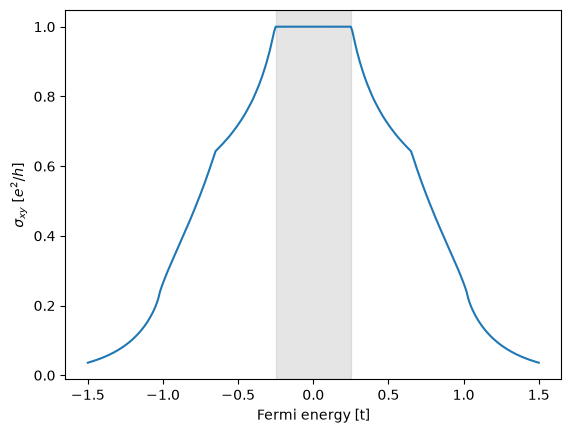

In [2]:
g = geometry.honeycomb_lattice() # honeycomb lattice
h = g.get_hamiltonian(has_spin=False) # first-neighbor hopping, t=1
h.add_haldane(0.1) # complex second-neighbor hopping t2
h.add_sublattice_imbalance(0.2) # staggered onsite energy M
mus = np.linspace(-1.5,1.5,301) # Fermi energies
s = h.get_anomalous_hall_conductivity(fermi=mus,nk=64,T=1e-3) # in units of e^2/h
print("sigma_xy at mu=0:",s[150]," at mu=0.5:",s[200])

plt.plot(mus,s)
plt.axvspan(-0.25,0.25,color="gray",alpha=0.2) # the gap
plt.xlabel("Fermi energy [t]") ; plt.ylabel(r"$\sigma_{xy}$ [$e^2/h$]")
plt.show()

Inside the gap $\sigma_{xy}=1$, the Chern number. When the Fermi energy enters the upper band, the
states that are filled carry the opposite curvature, so $\sigma_{xy}$ goes down continuously; it does
the same when the lower band is emptied, and it vanishes once both bands are full or both are empty,
beyond the energies shown here. The two kinks are band features: at $\pm0.65t$ the Fermi energy
reaches the band edge of the other valley, where the gap is $M+4.5\,t_2$ instead of $|M-4.5\,t_2|$,
and at $\pm1.02t$ the saddle point of the bands at the M point. In a metal the value is not quantized,
and it is set by the curvature of the states below the Fermi energy.

### The topological transition seen from the metal
The staggered energy $M$ competes with $t_2$: the gap closes at $M_c=4.5\,t_2=0.45t$, and above it the
insulator is trivial. We compute $\sigma_{xy}$ as a function of the Fermi energy and of $M$. The k-mesh
is diagonalized once for all the Fermi energies of each $M$.

at mu=0, M=0.2: 0.999999983890756 , M=0.7: 5.3085121877978056e-08


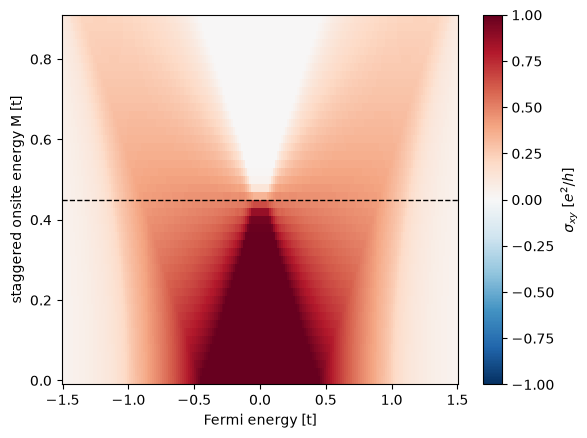

In [3]:
Ms = np.linspace(0.,0.9,46) # staggered onsite energies
mus = np.linspace(-1.5,1.5,201) # Fermi energies
smap = []
for M in Ms:
    h = g.get_hamiltonian(has_spin=False)
    h.add_haldane(0.1) ; h.add_sublattice_imbalance(M)
    smap.append(h.get_anomalous_hall_conductivity(fermi=mus,nk=64,T=1e-3))
smap = np.array(smap)
print("at mu=0, M=0.2:",smap[10,100],", M=0.7:",smap[35,100])

plt.pcolormesh(mus,Ms,smap,cmap="RdBu_r",shading="auto",vmin=-1,vmax=1)
plt.colorbar(label=r"$\sigma_{xy}$ [$e^2/h$]")
plt.axhline(0.45,color="black",ls="--",lw=1) # M_c, where the gap closes
plt.xlabel("Fermi energy [t]") ; plt.ylabel("staggered onsite energy M [t]")
plt.show()

Below $M_c$ the gap holds the plateau $\sigma_{xy}=1$, and it shrinks as $M$ grows, since the gap
$2|M_c-M|$ closes at the dashed line. Above $M_c$ the gap opens again with $\sigma_{xy}=0$, the trivial
insulator. In the metal there is no plateau, and $\sigma_{xy}$ changes smoothly across $M_c$ at a
Fermi energy inside a band: the anomalous Hall conductivity of a metal does not jump at the transition,
only its value inside the gap does.